# Komparasi_EulerRPY_1954_Madgwick-IMU-Palm_vs_IMU-UNIX-3DM-GX5-25

Perbandingan **roll / pitch / yaw** dari Madgwick IMU pada log Palm (`PLG1 v4`) terhadap sudut IMU 3DM-GX5-25, sesi **1954**.

- Palm: `261109195407.bin`.
- Acuan: `SensorConnectData_IMU_Unix_1954.csv` (waktu Unix, kolom `roll`, `pitch`, `yaw` dalam **rad**).
- Sumbu Palm: **X+ sama, Y+ dan Z+ dibalik**.
- Accel dan gyro. Magnetometer tidak dipakai. Gain Madgwick bawaan **0,033**.
- `ahrs` NED membandingkan akselerometer dengan `[0, 0, +1]`. Sensor membaca gaya spesifik (Z ≈ −1 g), jadi **tanda akselerasi dibalik hanya untuk filter**. Gyro dan magnetometer tidak ikut dibalik tandanya.
- `start_unix_ms` Palm adalah jam dinding WIB yang ditulis sebagai angka Unix. IMU 3DM adalah Unix UTC, jadi waktu Palm digeser **−7 jam**.

In [1]:
from pathlib import Path
import struct

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ahrs.filters import Madgwick
from scipy.spatial.transform import Rotation

ROOT = Path(r"D:/Pengujian/Swimmer_Monitoring/Palm_Pressure_Motion")
PALM_BIN = ROOT / "test_data_analisa" / "Vs_3DM-GX5-25_Data" / "Palm_Sensor" / "261109195407.bin"
IMU_CSV = ROOT / "test_data_analisa" / "Vs_3DM-GX5-25_Data" / "3DM-GX5-25_IMU" / "SensorConnectData_IMU_Unix_1954.csv"

G = 9.80665
HEADER_SIZE = 256
RECORD_SIZE = 26
USE_MAG = False


## 1. Baca log Palm

Header 256 B: magic `PLG1`, versi, periode, `start_unix_ms` di offset 22.
Rekaman 26 B: `t_rel_ms` u32 + 11×int16.

- d3..d5 accel, satuan **mg**
- d6..d8 gyro, satuan **0,1 °/s**
- d9..d11 magnetometer, satuan **µT**

In [2]:
def parse_plg1(path: Path) -> pd.DataFrame:
    raw = path.read_bytes()
    magic, version, period_ms, channels, rec_size = struct.unpack_from("<4sHHBB", raw, 0)
    if magic != b"PLG1" or version < 4 or rec_size != RECORD_SIZE:
        raise ValueError(f"bukan PLG1 v4: {magic!r} v={version} rec={rec_size}")
    start_unix_ms = struct.unpack_from("<Q", raw, 22)[0]
    rows = []
    offset = HEADER_SIZE
    while offset + RECORD_SIZE <= len(raw):
        t_rel, *ch = struct.unpack_from("<I11h", raw, offset)
        rows.append((t_rel, *ch))
        offset += RECORD_SIZE
    cols = ["t_rel_ms"] + [f"d{i}" for i in range(1, 12)]
    df = pd.DataFrame(rows, columns=cols)
    df["unix_ms"] = start_unix_ms + df["t_rel_ms"]
    df["t_s"] = df["unix_ms"] / 1000.0
    print(
        f"Palm {path.name}: {len(df)} sampel, period={period_ms} ms, "
        f"start_unix_ms={start_unix_ms}"
    )
    print(f"  rentang {df['t_s'].iloc[0]:.3f} .. {df['t_s'].iloc[-1]:.3f} s")
    return df

palm = parse_plg1(PALM_BIN)
palm.head()


Palm 261109195407.bin: 7527 sampel, period=10 ms, start_unix_ms=1794254047479
  rentang 1794254047.489 .. 1794254120.985 s


,t_rel_ms,d1,d2,d3,d4,d5,d6,d7,d8,d9,d10,d11,unix_ms,t_s
0,10,0,0,-31,15,1032,0,-4,-2,-4,8,52,1794254047489,1.794254e+09
1,20,0,0,-33,16,1020,3,2,-2,-4,8,52,1794254047499,1.794254e+09
2,29,0,0,-34,16,1021,2,2,-2,-4,8,52,1794254047508,1.794254e+09
3,39,0,0,-32,15,1023,1,3,-2,-4,8,52,1794254047518,1.794254e+09
4,49,0,0,-33,16,1022,2,4,-2,-5,8,51,1794254047528,1.794254e+09


## 2. Satuan dan sumbu

Accel ke m/s², gyro ke rad/s, magnetometer tetap µT. `Y` dan `Z` dibalik.

In [3]:
axis = np.array([1.0, -1.0, -1.0])
acc_g = palm[["d3", "d4", "d5"]].to_numpy(dtype=float) / 1000.0 * axis
gyr_rads = np.deg2rad(palm[["d6", "d7", "d8"]].to_numpy(dtype=float) * 0.1) * axis
mag_uT = palm[["d9", "d10", "d11"]].to_numpy(dtype=float) * axis
acc_ms2 = -acc_g * G

print("Accel mean (g) setelah remap sumbu:", acc_g.mean(axis=0))
print("Accel mean (g) yang masuk filter:", (-acc_g).mean(axis=0))
print("Accel |a| mean (g):", np.linalg.norm(acc_g, axis=1).mean())
print("Gyro mean (rad/s):", gyr_rads.mean(axis=0))
if USE_MAG:
    print("Mag mean (µT):", mag_uT.mean(axis=0))
    print("|Mag| mean (µT):", np.linalg.norm(mag_uT, axis=1).mean())


Accel mean (g) setelah remap sumbu: [-0.04123821  0.047408   -1.0007788 ]
Accel mean (g) yang masuk filter: [ 0.04123821 -0.047408    1.0007788 ]
Accel |a| mean (g): 1.028680327822004
Gyro mean (rad/s): [-0.00755521 -0.02899004  0.02329865]


## 3. Madgwick

Frekuensi dari median `Δt` Palm. Quaternion `[w, x, y, z]` diubah ke Euler ZYX dalam radian.

In [4]:
dt = np.diff(palm["t_s"].to_numpy())
dt = dt[dt > 0]
freq = 1.0 / np.median(dt)
print(f"Frekuensi Palm: {freq:.2f} Hz (median dt={np.median(dt)*1000:.2f} ms)")

kwargs = dict(gyr=gyr_rads, acc=acc_ms2, frequency=float(freq))
if USE_MAG:
    kwargs["mag"] = mag_uT
filt = Madgwick(**kwargs)
print(f"Gain Madgwick: {filt.gain}")
q_xyzw = np.column_stack([filt.Q[:, 1], filt.Q[:, 2], filt.Q[:, 3], filt.Q[:, 0]])
euler = Rotation.from_quat(q_xyzw).as_euler("ZYX", degrees=False)
palm = palm.copy()
palm["yaw"] = euler[:, 0]
palm["pitch"] = euler[:, 1]
palm["roll"] = euler[:, 2]
print(palm[["roll", "pitch", "yaw"]].describe())


Frekuensi Palm: 100.00 Hz (median dt=10.00 ms)


Gain Madgwick: 0.033
              roll        pitch          yaw
count  7527.000000  7527.000000  7527.000000
mean     -0.034229    -0.057141     0.141353
std       0.220489     0.126916     0.131522
min      -0.744141    -0.709473    -0.378924
25%      -0.085563    -0.078925     0.048795
50%       0.014718    -0.032709     0.152905
75%       0.016054    -0.014671     0.245838
max       0.653768     0.397269     0.590228


## 4. Baca IMU 3DM (Unix)

Header SensorConnect dilewati sampai `DATA_START`. Kolom `roll`, `pitch`, dan `yaw` dalam radian.

In [5]:
def read_imu_unix(path: Path) -> pd.DataFrame:
    lines = path.read_text(encoding="utf-8", errors="replace").splitlines()
    start = next(i for i, line in enumerate(lines) if line.startswith("DATA_START"))
    header = lines[start + 1].split(",")
    rows = [line.split(",") for line in lines[start + 2 :] if line.strip()]
    df = pd.DataFrame(rows, columns=header)
    rename = {}
    for col in df.columns:
        if col == "Time":
            continue
        rename[col] = col.split(":")[-1]
    df = df.rename(columns=rename)
    for col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df["t_s"] = df["Time"] / 1e9
    keep = ["t_s", "roll", "pitch", "yaw"]
    df = df[keep].dropna()
    print(f"IMU {path.name}: {len(df)} sampel")
    print(f"  rentang {df['t_s'].iloc[0]:.3f} .. {df['t_s'].iloc[-1]:.3f} s")
    return df

imu = read_imu_unix(IMU_CSV)
imu.head()


IMU SensorConnectData_IMU_Unix_1954.csv: 4685 sampel
  rentang 1794228840.335 .. 1794228945.264 s


,t_s,roll,pitch,yaw
0,1.794229e+09,-0.014092,-0.000227,-1.285210
1,1.794229e+09,-0.014089,-0.000230,-1.285203
2,1.794229e+09,-0.014093,-0.000232,-1.285200
3,1.794229e+09,-0.014080,-0.000269,-1.285191
4,1.794229e+09,-0.014082,-0.000274,-1.285192


## 5. Selaraskan waktu

Waktu Palm dikurangi 7 jam. Sisa offset (detik, ditambahkan ke waktu Palm)
dicari di ±5 s supaya korelasi pitch maksimum. Selisih sudut dibungkus ke (−π, π].

In [6]:
def wrap(angle):
    return (angle + np.pi) % (2 * np.pi) - np.pi


def interp_imu(imu_df, t_query):
    out = {}
    for name in ("roll", "pitch", "yaw"):
        out[name] = np.interp(
            t_query,
            imu_df["t_s"].to_numpy(),
            imu_df[name].to_numpy(),
            left=np.nan,
            right=np.nan,
        )
    return pd.DataFrame(out)


WIB_OFFSET_S = 7 * 3600
palm_utc = palm["t_s"].to_numpy() - WIB_OFFSET_S
print(
    f"Palm sebagai WIB-as-UTC: {palm['t_s'].iloc[0]:.3f} .. {palm['t_s'].iloc[-1]:.3f}"
)
print(f"Palm setelah -7 jam:     {palm_utc[0]:.3f} .. {palm_utc[-1]:.3f}")


def score_offset(offset_s):
    aligned = interp_imu(imu, palm_utc + offset_s)
    mask = aligned["pitch"].notna().to_numpy()
    if mask.sum() < 50:
        return -np.inf
    return float(np.corrcoef(palm.loc[mask, "pitch"], aligned.loc[mask, "pitch"])[0, 1])


grid = np.arange(-5.0, 5.0 + 1e-9, 0.01)
scores = np.array([score_offset(dt_off) for dt_off in grid])
best = float(grid[int(np.nanargmax(scores))])
print(f"Sisa offset: {best:+.3f} s (korelasi pitch={np.nanmax(scores):.4f})")

imu_on_palm = interp_imu(imu, palm_utc + best)
valid = imu_on_palm["roll"].notna().to_numpy()
print(f"Sampel overlap: {int(valid.sum())} / {len(palm)}")


Palm sebagai WIB-as-UTC: 1794254047.489 .. 1794254120.985
Palm setelah -7 jam:     1794228847.489 .. 1794228920.985


Sisa offset: -0.160 s (korelasi pitch=0.9984)
Sampel overlap: 7527 / 7527


## 6. Metrik

Dua baris per sumbu: selisih langsung, lalu setelah mean-bias
(rata-rata selisih dibungkus dikurangi).

In [7]:
def metrics(ref, got, debias=False):
    err = wrap(got - ref)
    if debias:
        err = wrap(err - np.mean(err))
    ref_c = ref - np.mean(ref)
    got_c = got - np.mean(got)
    corr = float(np.corrcoef(ref_c, got_c)[0, 1]) if len(ref) > 2 else np.nan
    return {
        "n": int(len(err)),
        "corr": corr,
        "mae_deg": float(np.rad2deg(np.mean(np.abs(err)))),
        "rmse_deg": float(np.rad2deg(np.sqrt(np.mean(err**2)))),
        "bias_deg": float(np.rad2deg(np.mean(err))),
    }


rows = []
for name in ("roll", "pitch", "yaw"):
    ref = imu_on_palm.loc[valid, name].to_numpy()
    got = palm.loc[valid, name].to_numpy()
    rows.append({"axis": name, "stage": "langsung", **metrics(ref, got)})
    rows.append({"axis": name, "stage": "setelah bias", **metrics(ref, got, debias=True)})

summary = pd.DataFrame(rows)
summary


,axis,stage,n,corr,mae_deg,rmse_deg,bias_deg
0,roll,langsung,7527,0.999178,1.600374,1.691196,1.593729e+00
1,roll,setelah bias,7527,0.999178,0.390664,0.565839,-5.655446e-15
2,pitch,langsung,7527,0.998376,1.813726,1.871092,-1.813726e+00
3,pitch,setelah bias,7527,0.998376,0.316902,0.459767,-6.152368e-16
4,yaw,langsung,7527,0.367881,71.573564,72.178265,7.157356e+01
5,yaw,setelah bias,7527,0.367881,7.875420,9.323461,1.644237e-14


## 7. Plot

Waktu diplot relatif terhadap awal overlap, dalam detik.

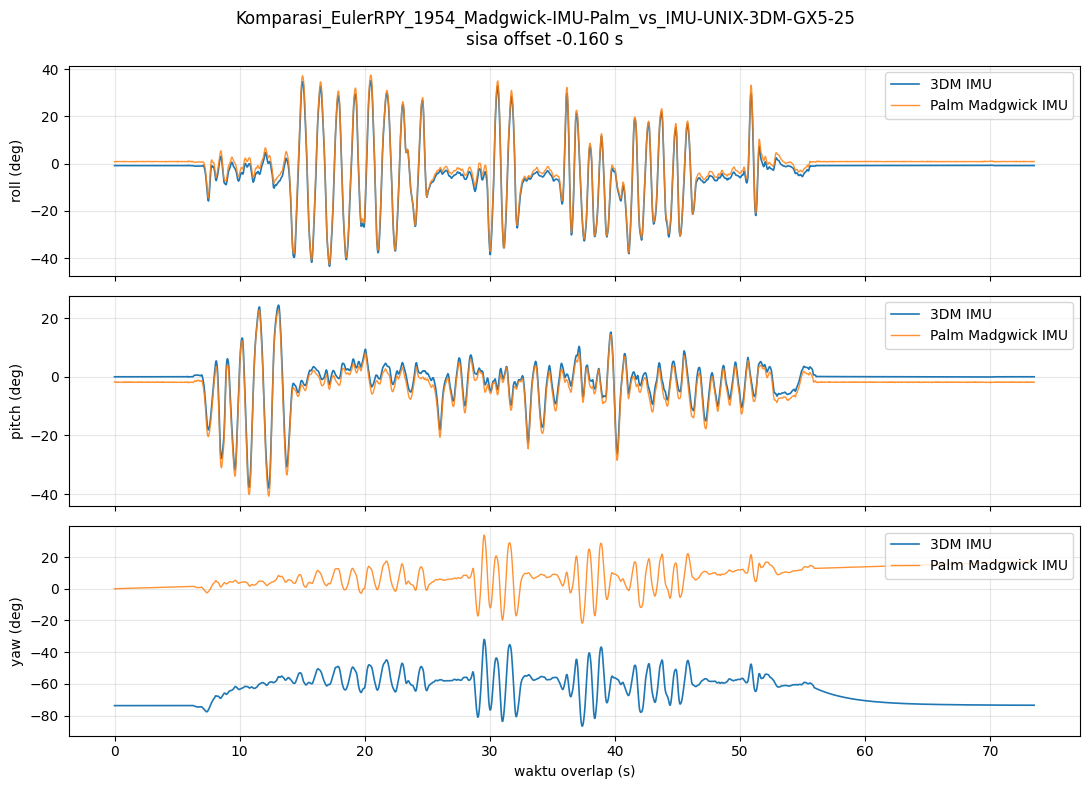

In [8]:
t_aligned = palm_utc + best
t0 = t_aligned[valid][0]
t_rel = t_aligned[valid] - t0

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, name in zip(axes, ("roll", "pitch", "yaw")):
    ax.plot(t_rel, np.rad2deg(imu_on_palm.loc[valid, name]), label="3DM IMU", lw=1.2)
    ax.plot(t_rel, np.rad2deg(palm.loc[valid, name]), label="Palm Madgwick IMU", lw=1.0, alpha=0.85)
    ax.set_ylabel(f"{name} (deg)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")
axes[-1].set_xlabel("waktu overlap (s)")
fig.suptitle("Komparasi_EulerRPY_1954_Madgwick-IMU-Palm_vs_IMU-UNIX-3DM-GX5-25\nsisa offset " + f"{best:+.3f} s")
fig.tight_layout()
plt.show()
